# AgentV5: what must a measurement distinguish?

Algorithm design informed by **DSI-Bench, Dyn-Bench and VLM4D together**.
No model training, threshold fitting, or train-on-two/test-on-third protocol.
This notebook reads the full corpus audit, recorded V5 traces, exact synthetic
counterexamples, and a five-clip cached-geometry comparison. It performs no
model inference and does not select benchmark answers.

Read `FINDINGS.md` beside this notebook for interpretation and design decisions.
Lexical screens retrieve examples; they are not validated coverage labels.
The casebook reviews language, not video ground truth. Synthetic failures and
disagreements between estimated tracks do not measure benchmark error rates.


In [1]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "d4rt_agent").is_dir())
RESEARCH = ROOT / "d4rt_agent/agent_v5/research"
OUT = ROOT / "d4rt_agent/results/agent_v5_capability_research_20261013"
def read(name):
    return json.loads((OUT / name).read_text())
corpus = read("corpus_blind.json")
traces = read("trace_rows.json")
counts = read("census.json")
counter = read("counterexamples.json")
pd.set_option("display.max_colwidth", 120)
assert len(corpus) == 10585 and len(traces) == 5416
assert not any("answer" in r or "gold" in r for r in corpus)
display(pd.DataFrame({b: {k: v for k, v in d.items() if k in ("questions", "clips")}
                      for b, d in counts.items()}).T)


,questions,clips
DSI,1769,943
Dyn,7000,1000
VLM4D,1816,1000


## Which distinctions appear only in the options?

Each screen is independently applied to the question and option text. Flags
overlap and include contextual mentions. The narrow `absence` screen misses
many short phrasings such as "no bus there". The separate existing text-only
absence parser identifies 795 VLM4D questions with an absence option.


In [2]:
screen_table = pd.DataFrame([
    {"screen": flag, **{b: d["screens"][flag]["either"] for b, d in counts.items()},
     **{b + " options only": d["screens"][flag]["options_only"] for b, d in counts.items()}}
    for flag in counts["DSI"]["screens"]
]).set_index("screen")
display(screen_table)
from vlm4d_dataset_exploration.taxonomy import is_absent
print("VLM4D presence/absence alternatives:", sum(any(is_absent(v) for v in r["options"].values())
                                               for r in corpus if r["benchmark"] == "VLM4D"))


,DSI,Dyn,VLM4D,DSI options only,Dyn options only,VLM4D options only
screen,,,,,,
absence,0,15,229,0,15,229
own_frame,1631,27,90,0,22,1
camera_reference,0,357,237,0,197,189
rotation,414,672,317,414,572,18
count,0,220,254,0,4,0
repetition,0,4,62,0,4,0
anatomical_hand,0,2,66,0,2,1
signed_relation,0,809,56,0,721,50
region_path,0,961,18,0,731,5


VLM4D presence/absence alternatives: 795


## What did the recorded agent actually attempt?

Accuracy is descriptive; these runs have different coverage. A missing
`available=False` flag does not prove that the tool measured the right thing.
Frames below count calls, not distinct questions. Compare kinds and frames
with the casebook's requirements before attributing an error to perception.


In [3]:
summary = read("trace_summary.json")
overall = pd.DataFrame([{ "benchmark": b, **{k: v for k, v in s["overall"].items()
                                           if k not in ("kinds", "track_frames")}}
                        for b, s in summary.items()]).set_index("benchmark")
overall["accuracy"] = overall["correct"] / overall["n"]
display(overall)
display(pd.DataFrame({b: s["overall"]["track_frames"] for b, s in summary.items()}).fillna(0).astype(int))
corpus_by_id = {r["qid"]: r for r in corpus}
own_subject = [r for r in traces if r["benchmark"] == "DSI" and corpus_by_id[r["qid"]]["group"] in ("0", "1")]
print("DSI own-frame subject questions:", len(own_subject),
      "attempted own-frame:", sum("own" in r["track_frames"] for r in own_subject),
      "scene-frame only:", sum(bool(r["track_frames"]) and set(r["track_frames"]) == {"scene"} for r in own_subject))
kinds = pd.DataFrame(traces).groupby(["benchmark", "kind"]).agg(n=("correct", "size"), accuracy=("correct", "mean"))
display(kinds)


,n,correct,unanswered,no_measurement,any_unavailable,all_attempted_unavailable,accuracy
benchmark,,,,,,,
DSI,800,411,4,1,112,78,0.513750
Dyn,2800,1646,3,199,289,205,0.587857
VLM4D,1816,1000,24,139,354,280,0.550661


,DSI,Dyn,VLM4D
scene,307,226,1005
own,84,31,333
image,1,0,5
camera,0,2,11


DSI own-frame subject questions: 339 attempted own-frame: 74 scene-frame only: 262


n  accuracy
benchmark kind                                 
DSI       cam_subject_range        69  0.608696
          camera_path              84  0.428571
          camera_translation      248  0.564516
          camera_viewpoint         31  0.677419
          scene_revisit             2  0.000000
          semantic                  1  1.000000
          subject_direction       290  0.400000
          subject_motion_profile    1  1.000000
          traj_subject_own_frame   74  0.729730
Dyn       apparent_size           146  0.684932
          cam_subject_elevation    82  0.353659
          cam_subject_range       295  0.511864
          camera_path             282  0.599291
          camera_rhythm           127  0.566929
          camera_shake             84  0.404762
          camera_translation       56  0.517857
          camera_viewpoint         72  0.388889
          camera_zoom              68  0.911765
          event_order              92  0.673913
          instance_count           48  0.437500
          landmark_relation        77  0.623377
          metric_distance          60  0.333333
          metric_speed             93  0.247312
          orbit_direction          17  0.470588
          pair_relation           406  0.564039
          scene_revisit            60  0.716667
          semantic                163  0.754601
          subject_direction       156  0.615385
          subject_motion_profile  252  0.714286
          subject_visibility      106  0.754717
          tracked_objects_count    27  0.555556
          traj_subject_own_frame   31  0.774194
VLM4D     apparent_size             1  0.000000
          cam_subject_range        86  0.720930
          camera_path              11  0.545455
          camera_translation        5  0.800000
          camera_viewpoint         53  0.509434
          event_order              15  0.466667
          instance_count          206  0.373786
          landmark_relation        18  0.722222
          metric_distance           1  1.000000
          metric_speed              2  0.000000
          orbit_direction           2  0.000000
          pair_relation            37  0.540541
          semantic                 57  0.701754
          subject_direction       952  0.576681
          subject_motion_profile   25  0.640000
          subject_visibility        2  0.500000
          tracked_objects_count    20  0.600000
          traj_subject_own_frame  323  0.510836

## Exact counterexamples against current code

These use production measurement functions with synthetic inputs. The
experiment does not change thresholds. Twelve reproduced failures include
information loss, a misleading report, unsupported schema predicates, and
wrong time/identity semantics; they are not twelve independent accuracy gains.


,case,reproduced,production_function,invariant
0,range_cannot_identify_side,True,measure_range,Left/right reflection must reverse signed side.
1,net_displacement_is_not_speed,True,tool_speed / measure_metric_speed,Mean speed is distance travelled / duration.
2,camera_return_is_not_static,True,tool_camera_motion / measure_camera_motion,Returning to the starting pose does not erase the path.
3,image_track_requires_no_depth,True,tool_entity_track / _first_present,A valid 2D track supports image displacement without 3D.
4,event_window_ignored,True,tool_event_onset / measure_event_onset,"An entry requested during [3,5] seconds must be in that interval."
5,last_leave_is_not_first_leave,True,measure_event_onset,"Ordering first events needs first transition, not last presence."
6,declared_stop_predicate_has_no_measurement,True,tool_event_onset,A declared geometric predicate needs a usable signal.
7,count_window_ignored,True,tool_count / measure_instances,"Count in [0,1.5] seconds excludes entities visible only after 3 seconds."
8,orientation_wrap_loses_turn_count,True,tool_orientation,A 360 degree turn requires unwrapped cumulative rotation.
9,irregular_timestamps_need_actual_dt,True,windowed_speed as called by measure_motion_profile,Constant velocity is invariant to temporal resampling.


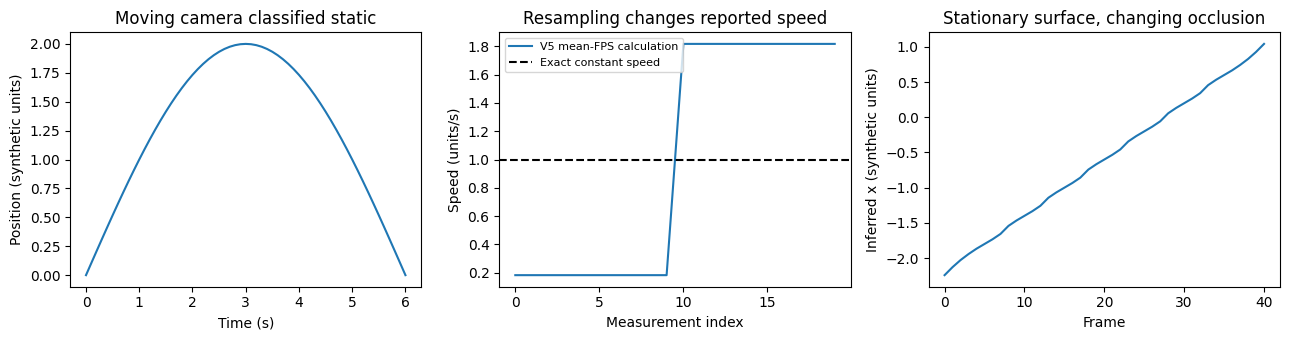

In [4]:
display(pd.DataFrame([{k: r[k] for k in ("case", "reproduced", "production_function", "invariant")}
                      for r in counter["cases"]]))
series = counter["series"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].plot(series["time"], series["return_path_x"])
axes[0].set(title="Moving camera classified static", xlabel="Time (s)", ylabel="Position (synthetic units)")
axes[1].plot(series["irregular_measured_speed"], label="V5 mean-FPS calculation")
axes[1].axhline(1, color="black", linestyle="--", label="Exact constant speed")
axes[1].set(title="Resampling changes reported speed", xlabel="Measurement index", ylabel="Speed (units/s)")
axes[1].legend(fontsize=8)
axes[2].plot(series["surface_x"], label="Visible-surface median")
axes[2].set(title="Stationary surface, changing occlusion", xlabel="Frame", ylabel="Inferred x (synthetic units)")
fig.tight_layout()
fig.savefig(OUT / "synthetic_diagnostics.png", dpi=160)
plt.show()


## Review the evidence requirements of actual questions

Change `selected_id` below to inspect any of the 32 curated cases. These
annotations preserve uncertainty about frame/turn semantics. They do not
infer the answer or treat previous rule labels as truth.


In [5]:
annotations = json.loads((RESEARCH / "casebook.json").read_text())["cases"]
by_id = {r["qid"]: r for r in corpus}
trace_by_id = {r["qid"]: r for r in traces}
assert len(annotations) == 32 and all(r["qid"] in by_id for r in annotations)
reviewed = [{**by_id[a["qid"]], **a, "recorded_kind": trace_by_id.get(a["qid"], {}).get("kind")}
            for a in annotations]
display(pd.DataFrame(reviewed)[["benchmark", "question", "needs", "recorded_kind", "finding"]])
selected_id = "vlm4d_real_davis-baseball_3"
display(by_id[selected_id])
display(next(a for a in annotations if a["qid"] == selected_id))


,benchmark,question,needs,recorded_kind,finding
0,DSI,"In this video clip, how is the submarine's location moving in the 3D scene relative to his/her/its starting orientat...","[subject translation in initial body frame, turn direction]",subject_direction,One option conjoins translation and turning. Resolve whether turning denotes heading of the path or body rotation be...
1,DSI,"In this video clip, how is the character's location moving in the 3D scene relative to his/her/its starting orientat...","[camera compensation, initial body frame, translation and turn]",subject_direction,Moving-camera version should use the same task recipe and different evidence reliability; it should not be a benchma...
2,DSI,"In this video clip, relative to its starting orientation and location, how is the observer's location moving?","[camera trajectory, orbit geometry and reference, static alternative]",camera_translation,Orbit needs a defined centre or a documented path convention. Sideways translation plus opposing pan is not sufficient.
3,DSI,"In this video clip, relative to its starting orientation and location, how is the observer's location moving?","[camera translation, camera orientation]",camera_translation,A dominant pan label discards the forward/backward distinction required by every option.
4,DSI,How does the distance between the observer and the character change in this video?,"[subject-camera range trend, unknown alternative]",None,"Existing scalar range is appropriate. Unreliable geometry should support unknown, not a fabricated trend."
5,DSI,"In this video, how does the observer's position change relative to the character's own orientation?","[subject position, subject orientation over time, camera bearing in subject frame]",None,Bearing depends on both parties and the frame anchor; it is not the same quantity as subject heading change.
6,Dyn,"Between 0.0s and 1.5s, how does the relative position of the boxer in blue headgear change with respect to the referee?","[two identities, signed relative position, reference-body frame, interval]",pair_relation,Distance cannot distinguish the referee's left/right. Even a new image-relative-position tool would not resolve the ...
7,Dyn,"At the beginning of the video, where is the person in the orange shirt relative to the person in the white tank top?","[two identities, signed relative position, initial instant, frame disambiguation]",pair_relation,"Options require lateral and depth components together, not just one nearest axis."
8,Dyn,Which interval shows the smoothest camera motion with the lowest acceleration variance?,"[camera pose time series, actual timestamps, acceleration variance, compare four intervals]",camera_rhythm,Existing whole-window rhythm/shake labels cannot directly rank four option-defined windows.
9,Dyn,Which phase of the video exhibits the smoothest camera motion with the lowest acceleration variance?,"[option-specific phases, camera acceleration variance, rotation/translation distinction]",None,Phase percentages and literal timestamps are not perfectly consistent. Preserve the ambiguity and explicit intervals...


{'benchmark': 'VLM4D',
 'qid': 'vlm4d_real_davis-baseball_3',
 'source': 'davis',
 'video': 'videos_real/davis/baseball.mp4',
 'group': 'real',
 'question': 'How many times does the batter hit the ball to the left?',
 'options': {'A': '1', 'B': '2', 'C': '3', 'D': '0'},
 'question_hits': ['count', 'repetition'],
 'option_hits': [],
 'hits': ['count', 'repetition']}

{'qid': 'vlm4d_real_davis-baseball_3',
 'needs': ['hit occurrences',
  'ball direction conditional on each hit',
  'count qualifying events'],
 'finding': 'Count ball-hit events, not bat motion cycles, balls, or people.'}

## Cached tracks: a diagnostic, not a replacement algorithm

Fixed-seed Point4D displacement and visible-surface medians use different
correspondences. Neither is ground truth. The seed comparison uses the
existing frame-0 query grid without a fitted confidence threshold. Mask
membership is an agreement check; projected points inside a mask can still
have incorrect depth, and correct hidden points can lie outside the visible mask.


,clip,status,instances,seed_points,mask_membership_fraction,net_disagreement_scales
0,varanus-tree,compared,1,53,0.473512,0.926601
1,bear_,compared,1,72,0.882283,0.079021
2,bike-packing,compared,1,49,0.747708,0.128369
3,bmx-trees,compared,1,13,0.409615,0.808020
4,carousel,compared,5,68,0.253410,0.992951


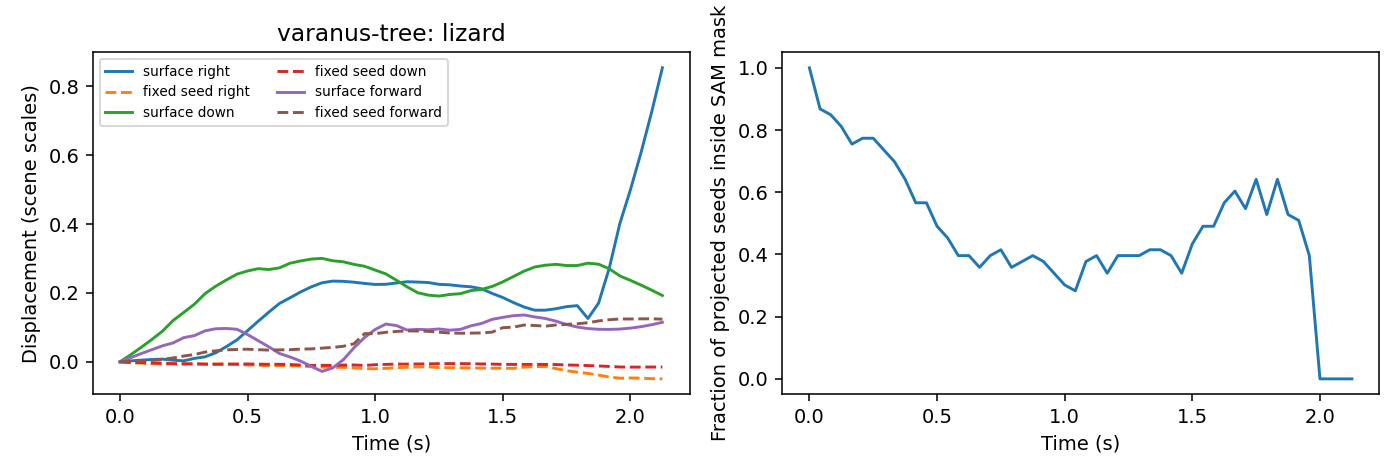

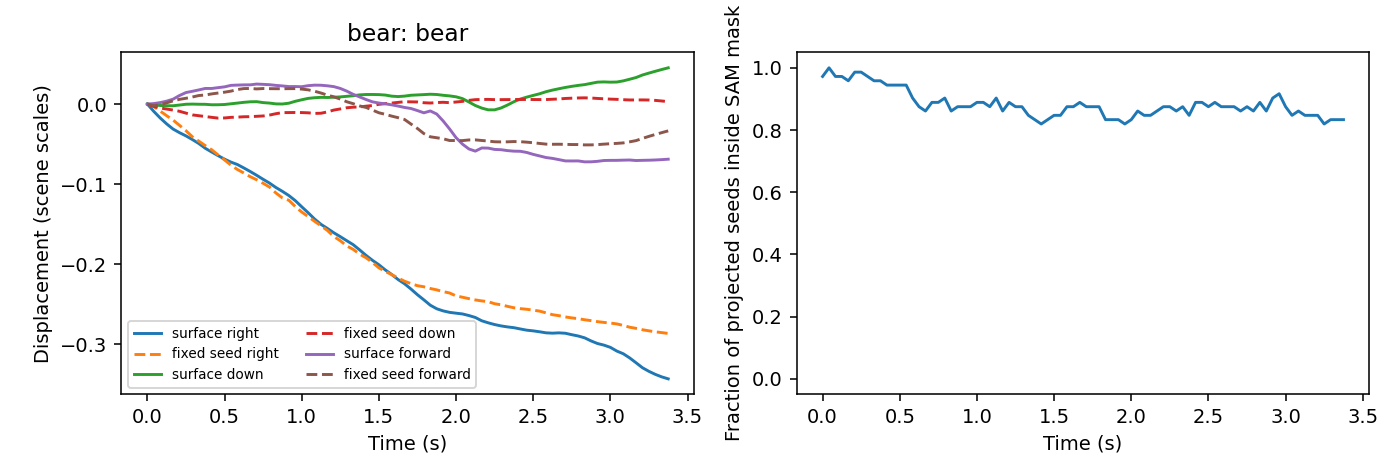

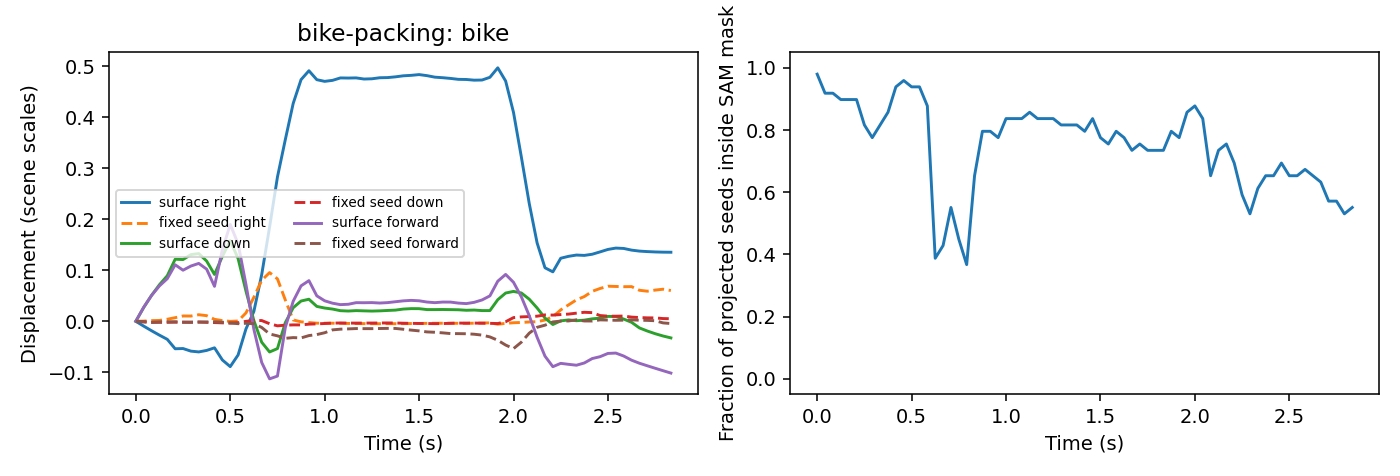

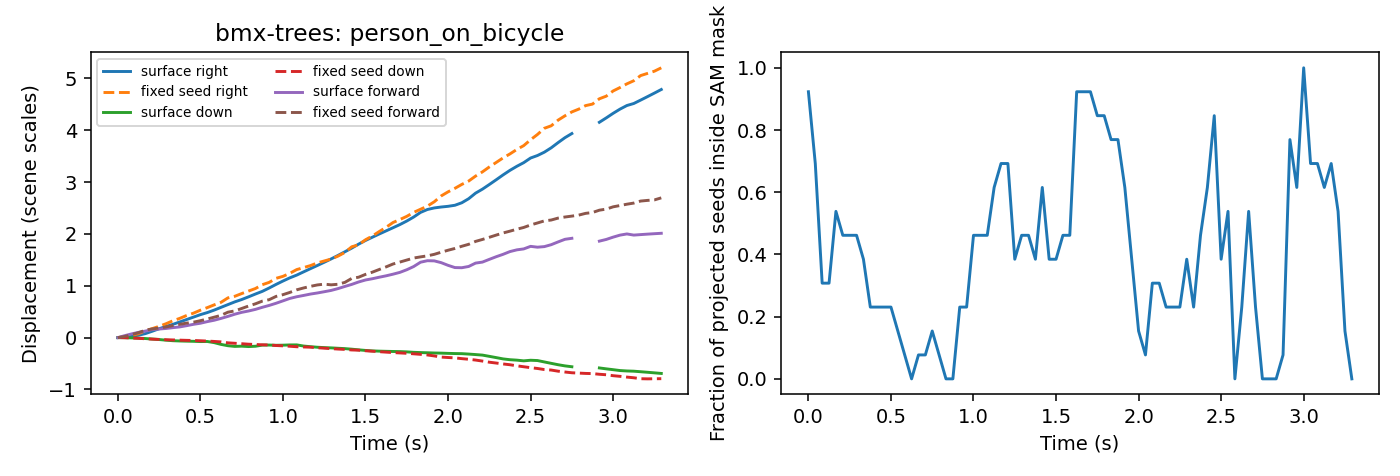

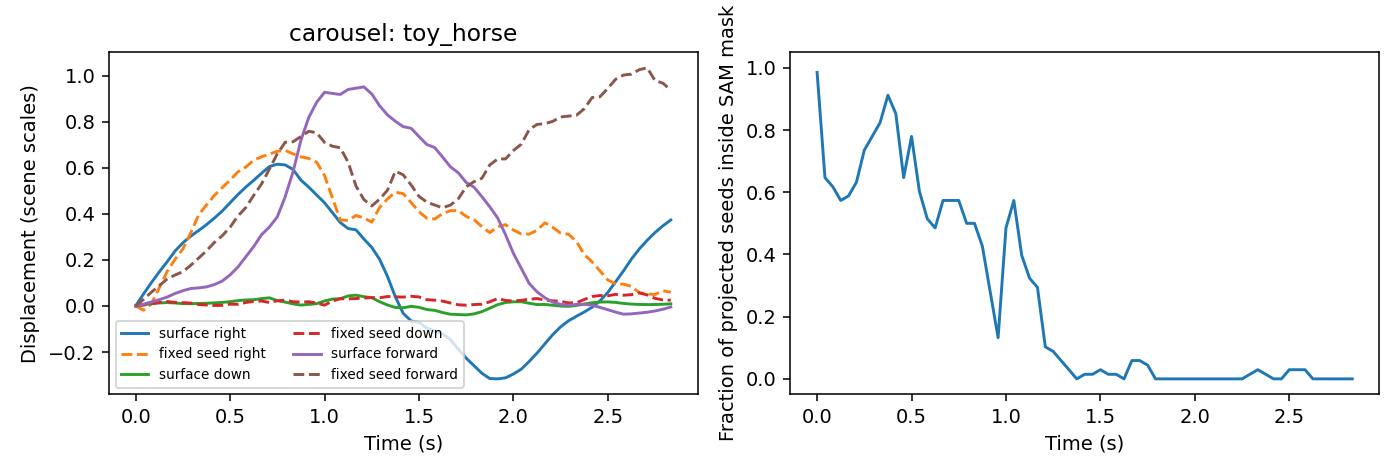

In [6]:
cached = read("cached_tracks.json")["cases"]
fields = ["clip", "status", "instances", "seed_points", "mask_membership_fraction", "net_disagreement_scales"]
display(pd.DataFrame(cached).reindex(columns=fields))
for r in cached:
    plot = OUT / ("tracks_" + r["clip"].strip("_") + ".png")
    if plot.exists():
        display(Image(filename=str(plot)))


## Next controlled comparisons

Use all three datasets to select diagnostic cases and guide the shared
algorithm. Separate fixes to frame/reduction semantics from new primitives,
routing changes, and reporting changes. Keep the model as the final answer
chooser. Compare matched questions, source clips, backbones and visual inputs;
include DSI reverse/flip augmentations and report each benchmark separately.

Reproduce the underlying CPU jobs with commands in `README.md`. This notebook
intentionally does not submit jobs or load perception models automatically.
